# Diabetes Progression Prediction Using Artificial Neural Networks

## Objective

The objective of this project is to develop an Artificial Neural
Network (ANN) regression model to predict diabetes disease
progression using the Diabetes dataset available in Scikit-learn.

The project involves data preprocessing, exploratory data analysis,
ANN model development, model evaluation, and hyperparameter tuning.

The performance of the models will be evaluated using Mean Squared
Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error
(MAE), and R-squared (R²) score.

In [1]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
# Load diabetes dataset
diabetes = load_diabetes()

# Convert features into DataFrame
df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

# Add target variable
df['target'] = diabetes.target

# Display first five rows
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
# Dataset information
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (442, 11)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Statistical Summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate Rows:
0


## Dataset Inspection and Initial Observations

The Diabetes dataset contains 442 observations and 11 columns,
including 10 independent features and one target variable.

The dataset contains no missing values or duplicate records.

The descriptive statistics indicate that the independent features
are already standardized in the original Scikit-learn dataset.
Their mean values are approximately zero.

The target variable has a mean of 152.13 and a standard deviation
of 77.09.

Since the dataset contains no missing values, no imputation is
required. Feature scaling will be performed after splitting the
dataset to prevent data leakage.

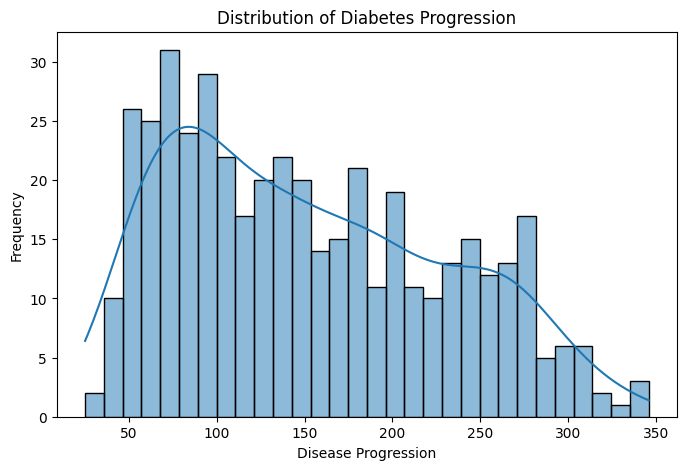

In [4]:
# EDA
# Target Distribution
plt.figure(figsize=(8, 5))

sns.histplot(df['target'], kde=True, bins=30)

plt.title('Distribution of Diabetes Progression')
plt.xlabel('Disease Progression')
plt.ylabel('Frequency')

plt.show()

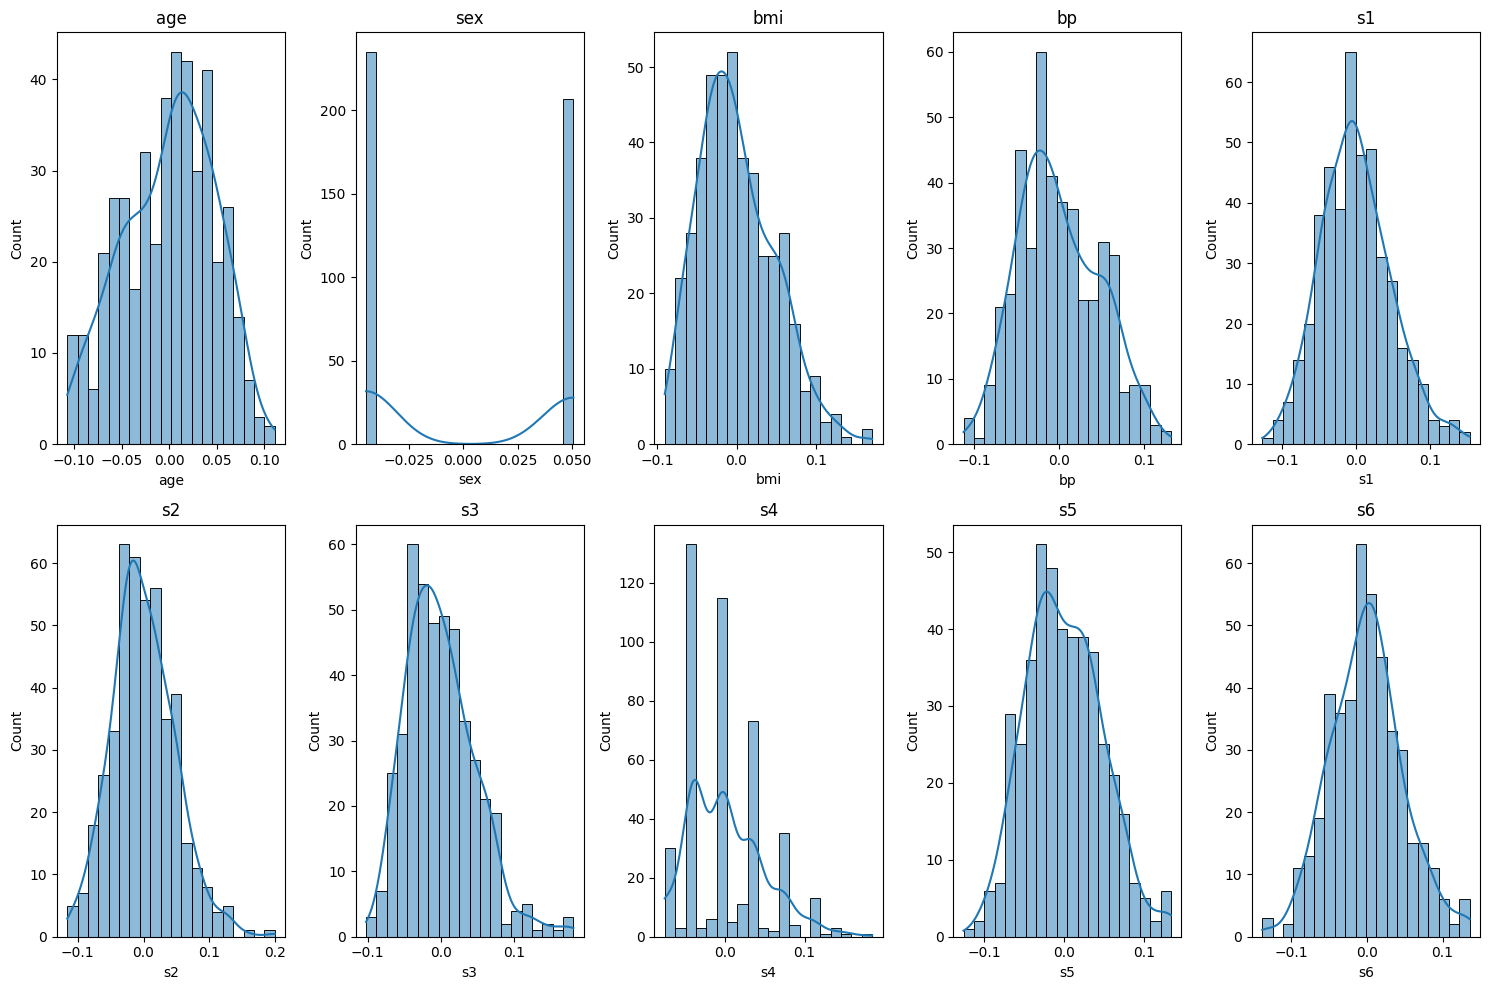

In [5]:
# Feature Distribution
plt.figure(figsize=(15, 10))

for i, column in enumerate(df.columns[:-1]):
    plt.subplot(2, 5, i + 1)

    sns.histplot(df[column], kde=True, bins=20)

    plt.title(column)

plt.tight_layout()
plt.show()

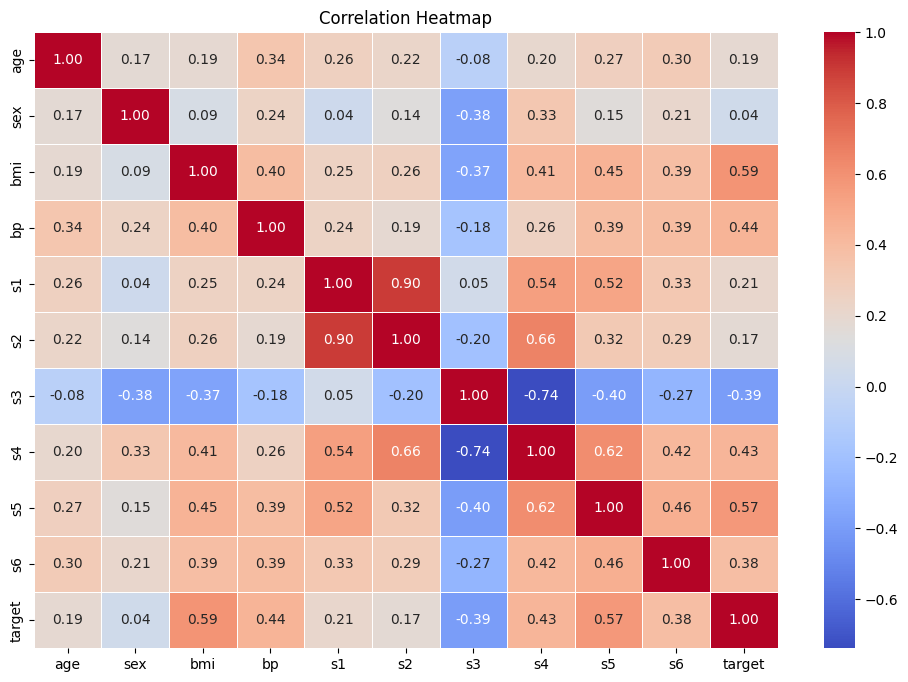

In [6]:
#Correlation
plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()

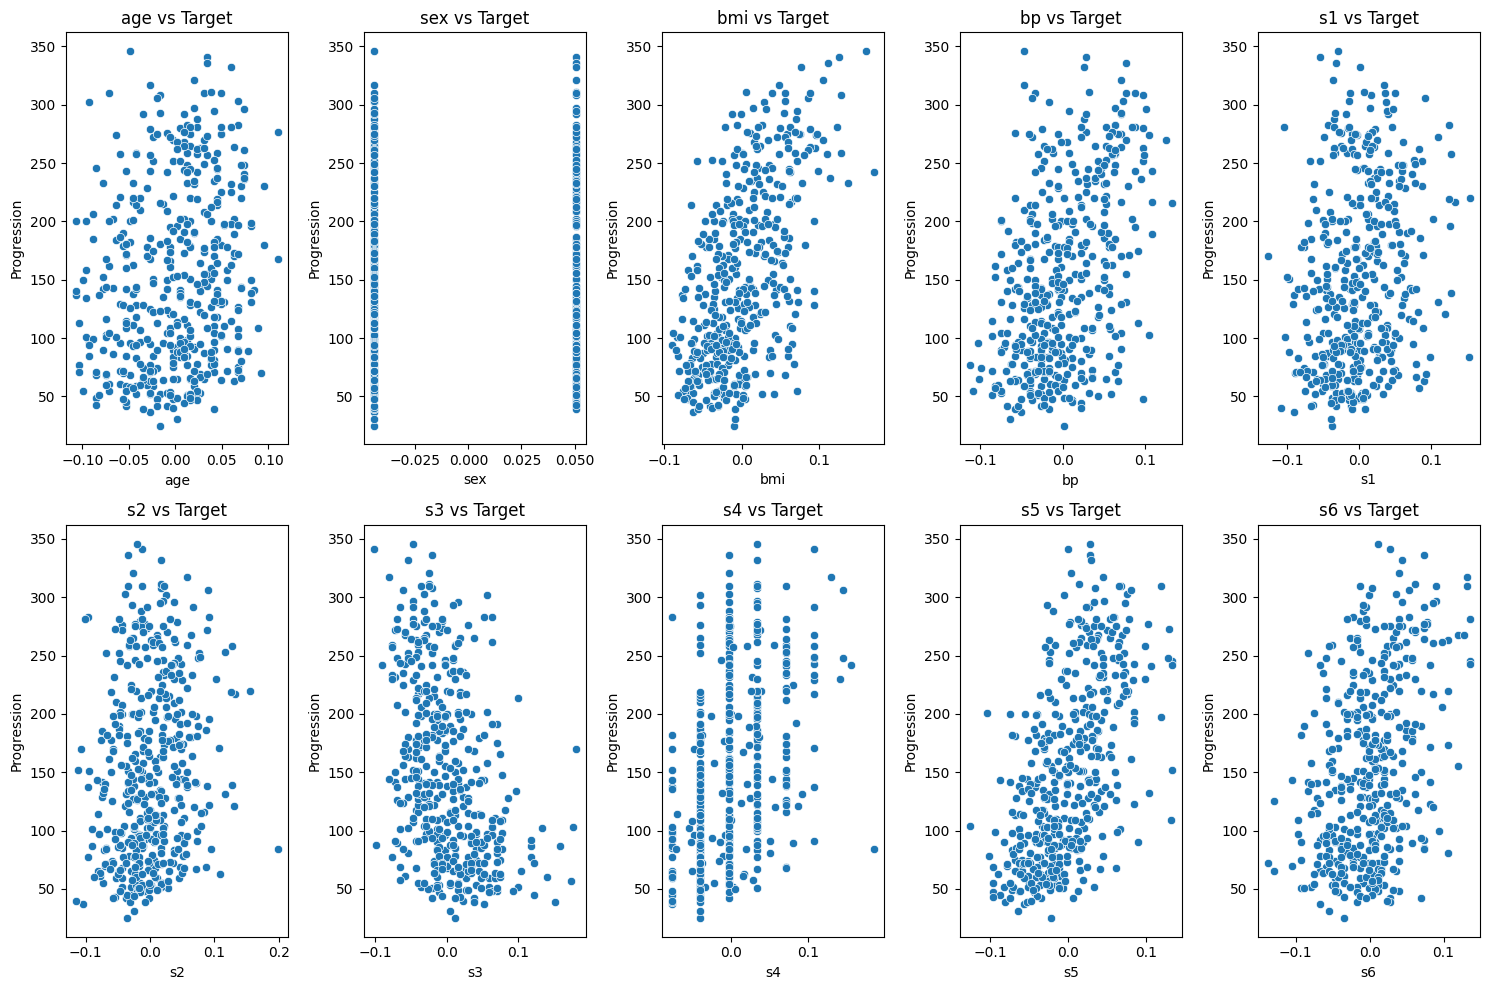

In [7]:
plt.figure(figsize=(15, 10))

for i, column in enumerate(df.columns[:-1]):
    plt.subplot(2, 5, i + 1)

    sns.scatterplot(
        x=df[column],
        y=df['target']
    )

    plt.title(f'{column} vs Target')
    plt.xlabel(column)
    plt.ylabel('Progression')

plt.tight_layout()
plt.show()

In [8]:
# Data Preprocessing
X = df.drop('target', axis=1)
y = df['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (442, 10)
Target shape: (442,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (353, 10)
Testing data: (89, 10)


In [10]:
# Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training scaled shape:", X_train_scaled.shape)
print("Testing scaled shape:", X_test_scaled.shape)

Training scaled shape: (353, 10)
Testing scaled shape: (89, 10)


In [11]:
# Building ANN Model
model = keras.Sequential([
    layers.Input(shape=(10,)),

    layers.Dense(64, activation='relu'),

    layers.Dense(32, activation='relu'),

    layers.Dense(1, activation='linear')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compiling Model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

In [13]:
#Training the model
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step - loss: 31180.9824 - mae: 157.6619 - val_loss: 22073.9785 - val_mae: 132.6728
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30681.8184 - mae: 156.2235 - val_loss: 21661.6895 - val_mae: 131.2499
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 29961.5352 - mae: 154.1485 - val_loss: 21030.0586 - val_mae: 129.0720
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 28831.0078 - mae: 150.8768 - val_loss: 20070.3848 - val_mae: 125.7425
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 27091.6191 - mae: 145.7640 - val_loss: 18657.2637 - val_mae: 120.7308
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 24578.5020 - mae: 138.0702 - val_loss: 16755.6211 - val_mae: 113.6604
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 21309.8867 - mae: 127.2625 - val_loss: 14406.8057 - val_mae: 104.1917
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 17507.7012 - mae: 113.3316 - val_loss

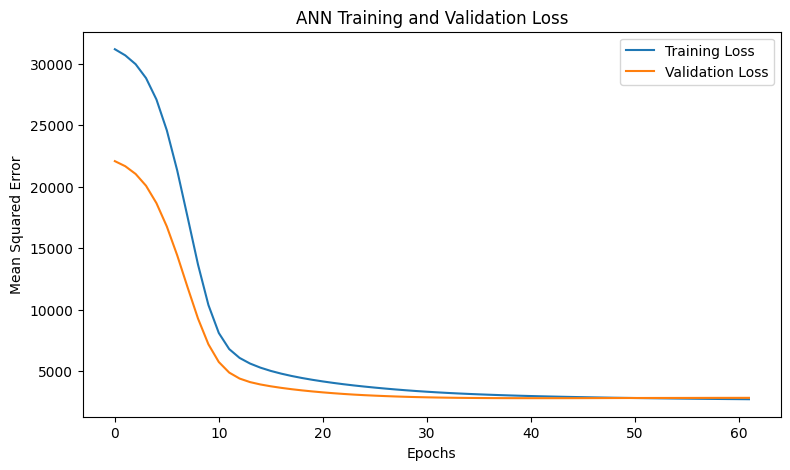

In [14]:
# Plot training and loss validation
plt.figure(figsize=(9, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')

plt.legend()
plt.show()

In [16]:
y_pred = model.predict(X_test_scaled)

# Convert predictions into a 1D array
y_pred = y_pred.flatten()

print("Actual values:", y_test.values[:10])
print("Predicted values:", y_pred[:10])

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 270ms/step
Actual values: [219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]
Predicted values: [168.23602  200.32674  135.21854  339.8169    79.35331  106.09051
 265.86444  180.63774   84.58094   69.158775]


In [17]:
# Calculate performance metrics
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Baseline ANN Performance")
print("------------------------")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("R2 Score:", round(r2, 4))

Baseline ANN Performance
------------------------
MSE: 3088.32
RMSE: 55.57
MAE: 44.14
R2 Score: 0.4171


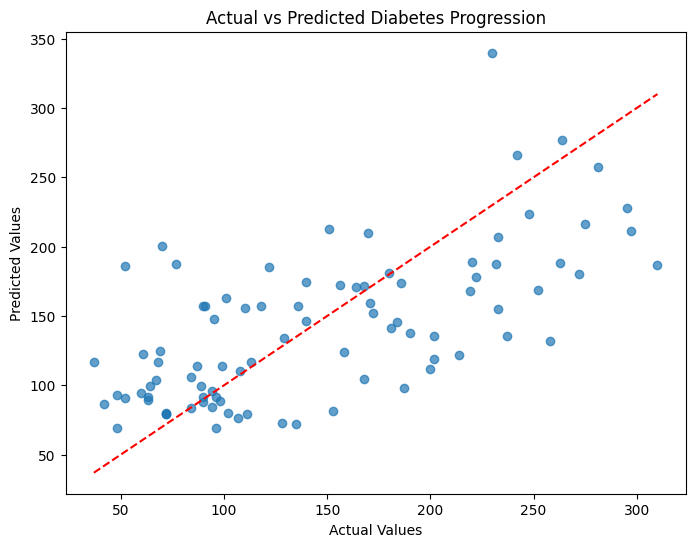

In [18]:
# Actual Vs Prediction
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Diabetes Progression")

plt.show()

In [19]:
# creating fuction for training improved models
def build_and_train_model(
    X_train,
    y_train,
    units1=32,
    units2=16,
    learning_rate=0.001,
    dropout_rate=0.0,
    l2_rate=0.0
):

    model = keras.Sequential([
        layers.Input(shape=(10,)),

        layers.Dense(
            units1,
            activation='relu',
            kernel_regularizer=keras.regularizers.l2(l2_rate)
        ),

        layers.Dropout(dropout_rate),

        layers.Dense(
            units2,
            activation='relu',
            kernel_regularizer=keras.regularizers.l2(l2_rate)
        ),

        layers.Dense(1, activation='linear')
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='mse',
        metrics=['mae']
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=20,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=300,
        batch_size=16,
        callbacks=[early_stopping],
        verbose=0
    )

    return model, history

In [20]:
#training model 2
model2, history2 = build_and_train_model(
    X_train_scaled,
    y_train,
    units1=32,
    units2=16,
    learning_rate=0.001
)

pred2 = model2.predict(X_test_scaled).flatten()

print("Model 2 Performance")
print("MSE:", mean_squared_error(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))
print("MAE:", mean_absolute_error(y_test, pred2))
print("R2:", r2_score(y_test, pred2))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 178ms/step
Model 2 Performance
MSE: 2972.3453860051227
RMSE: 54.51922033563138
MAE: 43.804022542546306
R2: 0.4389844747581395


In [21]:
#model 3
model3, history3 = build_and_train_model(
    X_train_scaled,
    y_train,
    units1=32,
    units2=16,
    learning_rate=0.0005,
    dropout_rate=0.2,
    l2_rate=0.001
)

pred3 = model3.predict(X_test_scaled).flatten()

print("Model 3 Performance")
print("MSE:", mean_squared_error(y_test, pred3))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred3)))
print("MAE:", mean_absolute_error(y_test, pred3))
print("R2:", r2_score(y_test, pred3))

1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
Model 3 Performance
MSE: 2921.1430247870153
RMSE: 54.047599620954635
MAE: 43.223188807455344
R2: 0.44864866779157675


In [22]:
# Comparing model 1, 2, 3
results = pd.DataFrame({
    'Model': ['Baseline ANN', 'Simplified ANN', 'Regularized ANN'],

    'MSE': [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, pred2),
        mean_squared_error(y_test, pred3)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, pred2)),
        np.sqrt(mean_squared_error(y_test, pred3))
    ],

    'MAE': [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, pred2),
        mean_absolute_error(y_test, pred3)
    ],

    'R2 Score': [
        r2_score(y_test, y_pred),
        r2_score(y_test, pred2),
        r2_score(y_test, pred3)
    ]
})

display(results.round(4))

,Model,MSE,RMSE,MAE,R2 Score
0,Baseline ANN,3088.3247,55.5727,44.1419,0.4171
1,Simplified ANN,2972.3454,54.5192,43.8040,0.4390
2,Regularized ANN,2921.1430,54.0476,43.2232,0.4486


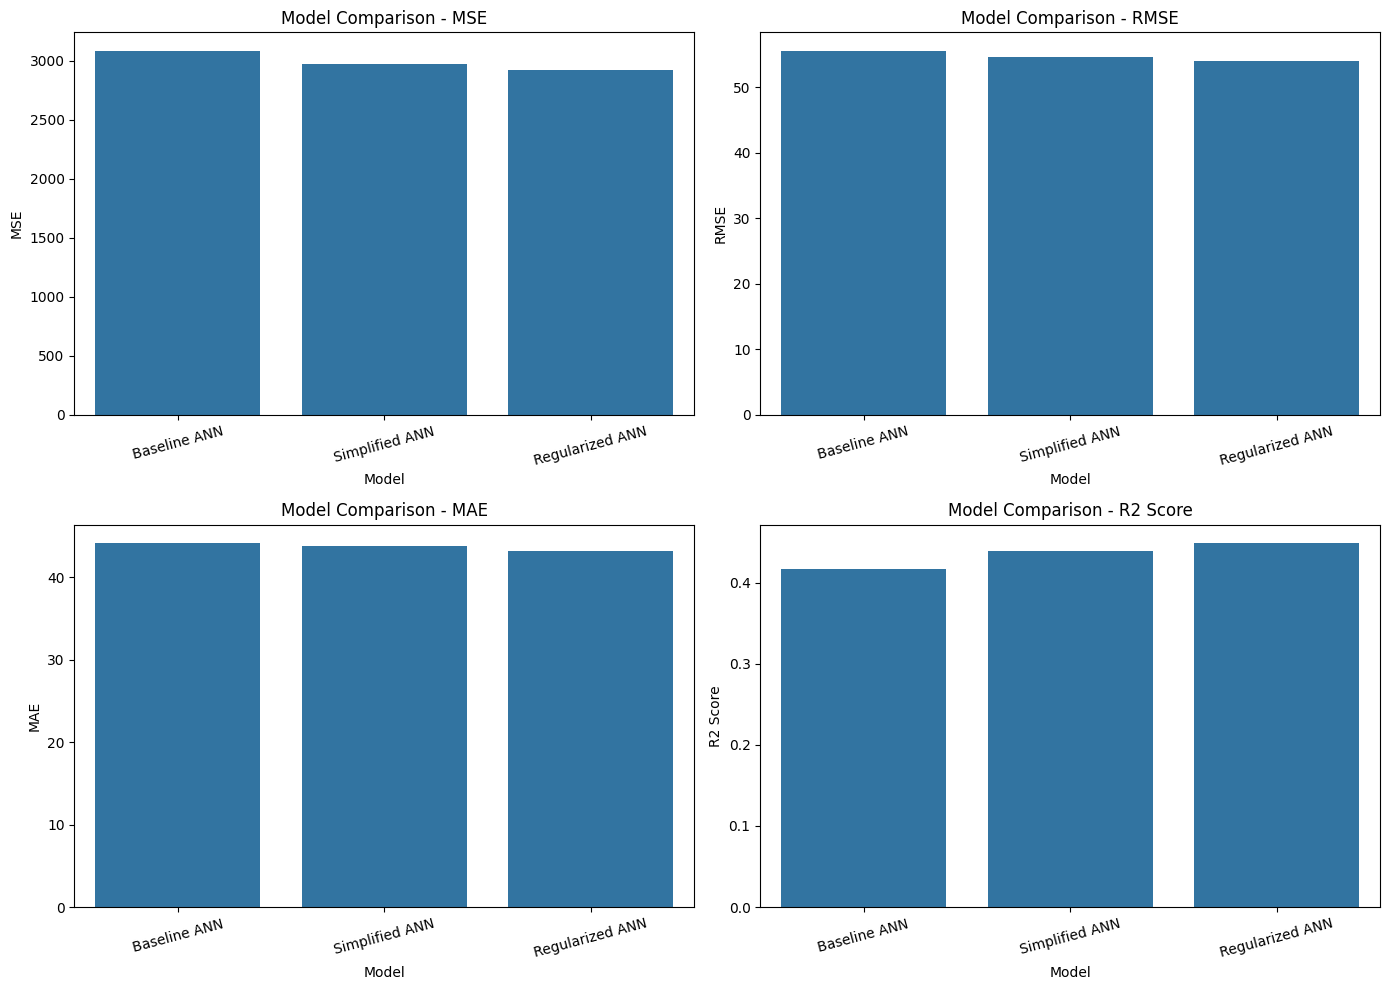

In [23]:
# Model comparison visualization

metrics = ['MSE', 'RMSE', 'MAE', 'R2 Score']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, metric in zip(axes.flatten(), metrics):

    sns.barplot(
        data=results,
        x='Model',
        y=metric,
        ax=ax
    )

    ax.set_title(f'Model Comparison - {metric}')
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## Best Model Selection

After comparing three ANN architectures, the Regularized ANN
achieved the best performance on the test dataset.

The model uses:
- 32 neurons in the first hidden layer.
- 16 neurons in the second hidden layer.
- ReLU activation function.
- Dropout rate of 0.2.
- L2 regularization of 0.001.
- Adam optimizer with learning rate 0.0005.
- Mean Squared Error loss function.

The model achieved an R2 score of 0.4486,
with an MSE of 2921.14 and MAE of 43.22.

Therefore, the Regularized ANN was selected as the
best-performing model among the three experiments.

# Conclusion

In this project, an Artificial Neural Network (ANN) regression model was developed to predict diabetes disease progression using the Scikit-learn Diabetes dataset.

The dataset contained 442 observations and 10 independent features. Data preprocessing included checking missing values, identifying duplicate records, splitting the dataset into training and testing sets, and standardizing the features.

Exploratory Data Analysis was performed to understand feature distributions and relationships between the independent variables and the target variable.

Three ANN architectures were developed and evaluated. The baseline ANN achieved an R² score of 0.4171. The simplified ANN improved the score to 0.4390, while the regularized ANN achieved the best R² score of 0.4486.

The final model achieved:
- MSE: 2921.14
- RMSE: 54.05
- MAE: 43.22
- R² Score: 0.4486

The experiments demonstrated that modifying the network architecture and applying regularization techniques can influence model performance.

Although the final model showed improvement, its predictive performance indicates that further experimentation and validation may be required.

This project demonstrates the application of Artificial Neural Networks to a regression problem involving diabetes progression data.

**Note:** The model predicts a quantitative disease progression measure and is intended for educational purposes. It is not a diagnostic or clinical decision-making tool.